Dataset Shape: (200, 10)
  student_id  gender           department  study_hours_per_week  \
0      S1000  Female          Business IT                  12.5   
1      S1001  Female     Computer Science                  13.5   
2      S1002    Male             Networks                  12.7   
3      S1003  Female          Business IT                  14.8   
4      S1004    Male  Information Systems                  21.4   

   attendance_pct  sleep_hours  previous_gpa internet_access part_time_job  \
0            73.5          6.3          1.87             Yes            No   
1            88.7          6.3          2.23             Yes            No   
2            92.9          7.1          2.63             Yes            No   
3            85.7          6.5          2.75             Yes            No   
4            79.1          7.8          2.82             Yes            No   

   exam_score  
0        50.2  
1        59.6  
2        56.2  
3        64.6  
4        66.2  

Target

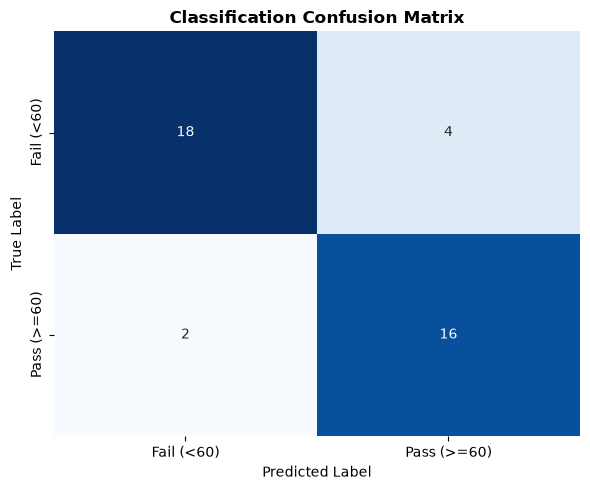

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Load Dataset using absolute path
df = pd.read_csv(r"C:\Users\user\CodeOrbit\Task 3\student_performance (1).csv")
print("Dataset Shape:", df.shape)
print(df.head())

# 2. Define Classification Target (1 if exam score >= 60, else 0)
df['passed_exam'] = (df['exam_score'] >= 60).astype(int)
print("\nTarget Class Distribution:\n", df['passed_exam'].value_counts(normalize=True))

# 3. Features & Train/Test Split
X = df[['study_hours_per_week', 'attendance_pct', 'previous_gpa', 'sleep_hours']]
y = df['passed_exam']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Simple Baseline Model (Predicts majority class for all)
baseline_pred = [y_train.mode()[0]] * len(y_test)
base_acc = accuracy_score(y_test, baseline_pred)
print(f"\nBaseline Accuracy: {base_acc:.2f}")

# 5. Train Logistic Regression Classifier
clf = LogisticRegression(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# 6. Evaluate Model Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\n--- Logistic Regression Model Performance ---")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")

# 7. Confusion Matrix Visualization
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Fail (<60)', 'Pass (>=60)'],
            yticklabels=['Fail (<60)', 'Pass (>=60)'])
plt.title('Classification Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('classification_confusion_matrix.png', dpi=300)
plt.show()